## MNIST Handwritten Digit Classification Using an Artificial Neural Network (ANN)

## Introduction

This project focuses on developing an Artificial Neural Network (ANN) to classify handwritten digits from 0 to 9 using the MNIST dataset.

The objective is to build, train, and evaluate a neural network capable of recognizing handwritten digits from grayscale images. The project also explores data preprocessing, model training, performance evaluation, and visualization of results.

The trained model is later integrated into an interactive Streamlit application called DigitVision, allowing users to draw digits and receive predictions.

## Step 1: Import libraries and load MNIST

The first step involves importing the required Python libraries and loading the MNIST dataset.

The following libraries are used:

- TensorFlow/Keras: Building and training the Artificial Neural Network.

- NumPy: Performing numerical operations.

- Pandas: Working with structured data.

- Matplotlib and Seaborn: Creating data visualizations.

- Scikit-learn: Evaluating model performance.

The MNIST dataset is loaded through TensorFlow Keras and automatically divided into training and testing sets.

In [25]:
# Import required libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Display dataset dimensions
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


### Dataset Overview

The MNIST dataset contains 70,000 grayscale images of handwritten digits:

- 60,000 training images used to train the model.
- 10,000 testing images used to evaluate the trained model.

Each image has dimensions of 28 × 28 pixels and represents one of ten digit classes (0–9).

The training data is used to help the neural network learn patterns associated with handwritten digits, while the testing data evaluates how well the model generalizes to previously unseen images.

## Step 2: Display 9 random handwritten digits

Before training the neural network, it is important to examine some sample images from the dataset.

The following visualization displays nine randomly selected handwritten digit images alongside their corresponding labels.

Each image is represented as a 28 × 28 grayscale pixel matrix, where pixel intensity determines the shade of each pixel. This provides an initial understanding of the image data that will be used to train the model.

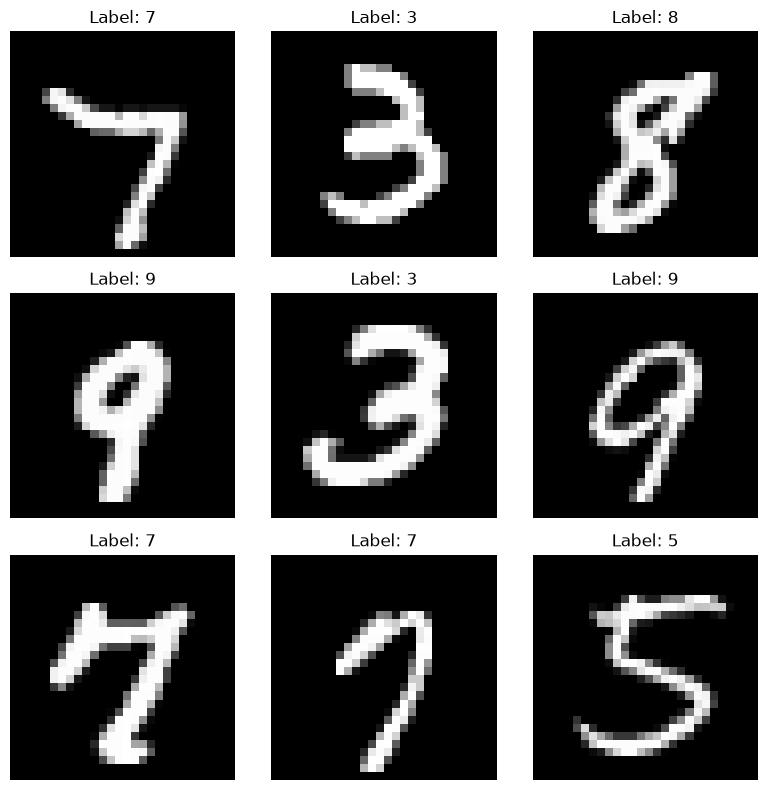

In [26]:
# Set random seed for reproducibility
np.random.seed(42)

# Select 9 random images
random_indices = np.random.choice(len(X_train), 9, replace=False)

# Create a 3x3 visualization
plt.figure(figsize=(8, 8))

for i, index in enumerate(random_indices):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[index], cmap="gray")
    plt.title(f"Label: {y_train[index]}")
    plt.axis("off")
    
plt.tight_layout()

from pathlib import Path

image_folder = Path("../images")
image_folder.mkdir(exist_ok=True)

plt.savefig(
    image_folder / "mnist_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The visualization shows examples of handwritten digits from 0 to 9. Although the images represent the same digit classes, handwriting styles vary in shape, size, thickness, and orientation.

These variations make handwritten digit recognition a classification task in which the model must learn relevant visual patterns rather than rely on identical image shapes.

## Step 3: Data Preprocessing

Two main preprocessing operations are performed:

## 3.1 Normalize the image data

The original pixel values range from 0 to 255. Dividing each pixel value by 255 scales the values to a range of 0 to 1.

This helps the neural network process the input data more consistently and supports efficient model training.

In [27]:
# Normalize pixel values to the range [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Check normalized pixel values
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 3.2 One-hot encode the labels

The digit labels are converted into categorical representations using one-hot encoding.

Since there are ten digit classes (0–9), each label is represented by a vector of ten elements, with the position corresponding to the correct digit set to 1 and the remaining positions set to 0.

In [28]:
# Convert labels into one-hot encoded vectors
y_train_encoded = to_categorical(y_train, num_classes=10)
y_test_encoded = to_categorical(y_test, num_classes=10)

# Display original and encoded labels
print("Original label:", y_train[0])
print("Encoded label:", y_train_encoded[0])

print("Training labels shape:", y_train_encoded.shape)
print("Testing labels shape:", y_test_encoded.shape)

Original label: 5
Encoded label: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Training labels shape: (60000, 10)
Testing labels shape: (10000, 10)


### Observation

After preprocessing, the image data is represented using normalized floating-point values, while the labels are represented as categorical vectors.

The images retain their original 28 × 28 dimensions. These transformations ensure that the data is in the appropriate format for training the ANN using categorical crossentropy as the loss function.

## 3.3 Confirm preprocessing

In [29]:
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("Training labels:", y_train_encoded.shape)
print("Testing labels:", y_test_encoded.shape)

print("Pixel range:", X_train.min(), "to", X_train.max())

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000, 10)
Testing labels: (10000, 10)
Pixel range: 0.0 to 1.0


## Step 4: Build the Artificial Neural Network (ANN)

A Sequential model is used to build the network by stacking layers in a linear order.



## 4.1 Import the required Keras components

In [30]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

## 4.2 Build the model

### Model Architecture

The network consists of the following layers:

1. **Flatten Layer:** Converts each 28 × 28 image into a one-dimensional vector containing 784 pixel values, making it suitable for processing by dense layers.

2. **First Dense Layer:** Contains 128 neurons with ReLU activation. It learns patterns and features from the input images.

3. **Dropout Layer:** Applies a dropout rate of 0.3, randomly excluding 30% of the layer's outputs during training. This helps reduce overfitting.

4. **Second Dense Layer:** Contains 64 neurons with ReLU activation, allowing the network to learn additional patterns.

5. **Output Layer:** Contains 10 neurons with Softmax activation. Each neuron represents one digit class from 0 to 9, and the output probabilities are used to determine the predicted digit.

### Activation Functions

- **ReLU (Rectified Linear Unit):** Introduces non-linearity by returning zero for negative inputs and the input value for positive inputs.
- **Softmax:** Converts the output values into probabilities across the ten digit classes, with the probabilities summing to 1.

In [31]:
# Initialize the ANN model
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

c:\Users\Admin\Documents\mnist-ann-handwritten-digit-classification\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Architecture Summary

The ANN uses two hidden dense layers with 128 and 64 neurons, respectively, followed by a 10-neuron output layer.

The network learns progressively from the image pixel values and produces probabilities for each digit class. The class with the highest predicted probability is selected as the model's prediction.

## Step 5: Compile the ANN Model

Before training, the neural network must be compiled by specifying an optimizer, loss function, and evaluation metric.

The following configurations are used:

- **Optimizer – Adam:** An adaptive optimization algorithm that updates the network's weights and biases to minimize prediction errors during training.
- **Loss Function – Categorical Crossentropy:** Measures the difference between the predicted class probabilities and the actual one-hot encoded labels. The model aims to minimize this loss.
- **Evaluation Metric – Accuracy:** Measures the proportion of correctly classified images during training and evaluation.

These configurations guide the learning process and provide a way to monitor the model's performance.

In [32]:
# Compile the ANN model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## Step 6: Configure Callbacks

Callbacks are functions that monitor and control the model's training process.

Two callbacks are implemented in this project:

### Early Stopping

Early Stopping monitors the model's validation loss during training.

The following parameters are used:

- **monitor = "val_loss":** Monitors the validation loss after each epoch.
- **patience = 5:** Allows training to continue for five consecutive epochs without improvement before stopping.
- **restore_best_weights = True:** Restores the model weights from the epoch with the lowest validation loss.

Early Stopping helps reduce unnecessary training and can limit overfitting.


### TensorBoard

The TensorBoard callback is configured to record training metrics and model information for later visualization.

In [33]:
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard
from datetime import datetime

# Create a unique TensorBoard log directory
log_dir = "logs/fit/" + datetime.now().strftime("%Y%m%d-%H%M%S")

# Configure Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Configure TensorBoard
tensorboard_callback = TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

print("Callbacks configured successfully!")

Callbacks configured successfully!


## Step 7: Train the ANN Model

The ANN is trained using the preprocessed MNIST training dataset.

The `model.fit()` function allows the network to learn patterns from the training images by adjusting its weights and biases to minimize prediction errors.

The following training configurations are used:

- **Epochs = 10:** The model is allowed to pass through the training dataset up to ten times.
- **Batch size = 128:** The model processes 128 training images before updating its weights.
- **Validation split = 0.1:** 10% of the training data is set aside for validation during training.
- **Callbacks:** Early Stopping monitors validation loss, while TensorBoard records training metrics.

The training process tracks accuracy and loss for both the training and validation datasets.

In [34]:
# Train the ANN model
history = model.fit(
    X_train,
    y_train_encoded,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[
        early_stopping,
        tensorboard_callback
    ],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.8657 - loss: 0.4465 - val_accuracy: 0.9568 - val_loss: 0.1487
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9412 - loss: 0.1985 - val_accuracy: 0.9683 - val_loss: 0.1088
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9548 - loss: 0.1530 - val_accuracy: 0.9747 - val_loss: 0.0864
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9602 - loss: 0.1296 - val_accuracy: 0.9747 - val_loss: 0.0842
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9658 - loss: 0.1118 - val_accuracy: 0.9763 - val_loss: 0.0757
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9697 - loss: 0.0978 - val_accuracy: 0.9775 - val_loss: 0.0784
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9741 - loss: 0.0862 - val_accuracy: 0.9788 - val_loss: 0.0696
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9753 - loss: 0.0788 - val_acc

### Training Results

The model achieved the following results during training:

- **Training Accuracy:** 97.74%
- **Validation Accuracy:** 97.95%
- **Training Loss:** 0.0710
- **Validation Loss:** 0.0661

The training and validation accuracy values are close, suggesting that the model learned effectively from the training data and performed similarly on the validation data.

The relatively small difference between training and validation loss also suggests that there is no substantial indication of overfitting based on these final metrics.

## Step 8: Visualize Training and Validation Performance

Two graphs are generated:

1. **Training vs. Validation Accuracy:** Shows how classification accuracy changes across epochs for both training and validation datasets.
2. **Training vs. Validation Loss:** Shows how prediction error changes across epochs for both datasets.

These visualizations help assess the model's learning progress and identify possible signs of overfitting or underfitting.

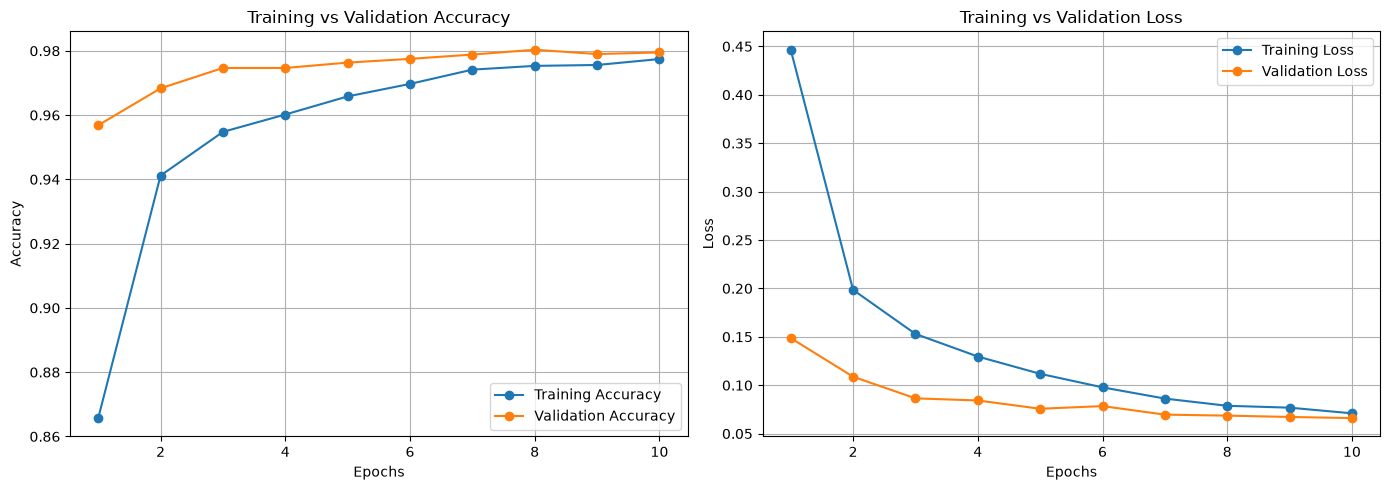

In [35]:
# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Create visualizations
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../images/training_history.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation of Training Graphs

**Training vs. Validation Accuracy**

The accuracy graph shows an overall increase in training and validation accuracy as the number of epochs increases. This indicates that the model progressively learns patterns that help it classify handwritten digits.

The training and validation accuracy curves remain relatively close, suggesting that the model generalizes reasonably well to unseen validation images.

**Training vs. Validation Loss**

The loss graph shows how prediction error changes during training. A decreasing loss indicates that the model is improving its predictions.

The relatively similar training and validation loss trends suggest that the model maintains consistent performance across both datasets, with no substantial indication of overfitting.

## Step 9: Evaluate the Model on Test Data

After training, the model is evaluated using the MNIST testing dataset, which contains 10,000 images that were not used during training.

The `model.evaluate()` function calculates the model's performance on this unseen data.

Two evaluation metrics are considered:

- **Test Accuracy:** Measures the proportion of test images correctly classified by the model.
- **Test Loss:** Measures the prediction error using categorical crossentropy.

Evaluating the model on unseen data helps assess its ability to generalize beyond the training dataset.

In [36]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9770 - loss: 0.0709
Test Loss: 0.0709
Test Accuracy: 0.9770
Test Accuracy (%): 97.70%


### Test Results and Interpretation

The model achieved:

- **Test Accuracy: 97.70%**
- **Test Loss: 0.0709**

The test accuracy indicates that the model correctly classified approximately 97.70% of the 10,000 test images.

The test loss of 0.0709 represents the categorical crossentropy error associated with the model's predictions.

These results demonstrate that the ANN performs well when classifying previously unseen handwritten digit images.

## Step 10: Generate predictions

After evaluating the model, predictions are generated using the testing dataset.

The `model.predict()` function passes the test images through the trained neural network and produces a probability distribution across the ten digit classes (0–9).

The predicted digit is determined by selecting the class with the highest probability using `argmax()`.

These predictions are then used to compare the model's output with the actual test labels and support further performance evaluation.

In [37]:
# Generate predictions for the test dataset
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted digit labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual digit labels
y_true = y_test

# Display the first 10 predictions alongside actual labels
print("Predicted labels:", y_pred[:10])
print("Actual labels:   ", y_true[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Predicted labels: [7 2 1 0 4 1 4 9 6 9]
Actual labels:    [7 2 1 0 4 1 4 9 5 9]


### Observation of Predicted and Actual Labels

The output displays the model's predicted labels alongside the actual labels for the first ten test images.

Comparing the two arrays shows that the model correctly classified nine out of the ten displayed images.

For the ninth image, the model predicted **6**, while the actual label was **5**, indicating a misclassification.

This comparison provides a simple illustration of how the model performs on individual test samples and shows that, despite achieving high overall accuracy, it can still make incorrect predictions.

## Step 11: Create the confusion matrix

In this project, the confusion matrix contains ten rows and ten columns, representing the digit classes from 0 to 9.

- **Rows:** Represent the actual digit labels.
- **Columns:** Represent the predicted digit labels.
- **Diagonal values:** Represent correctly classified images.
- **Off-diagonal values:** Represent incorrectly classified images.

The confusion matrix helps identify which digits the model classifies correctly and which digits it tends to confuse with others.

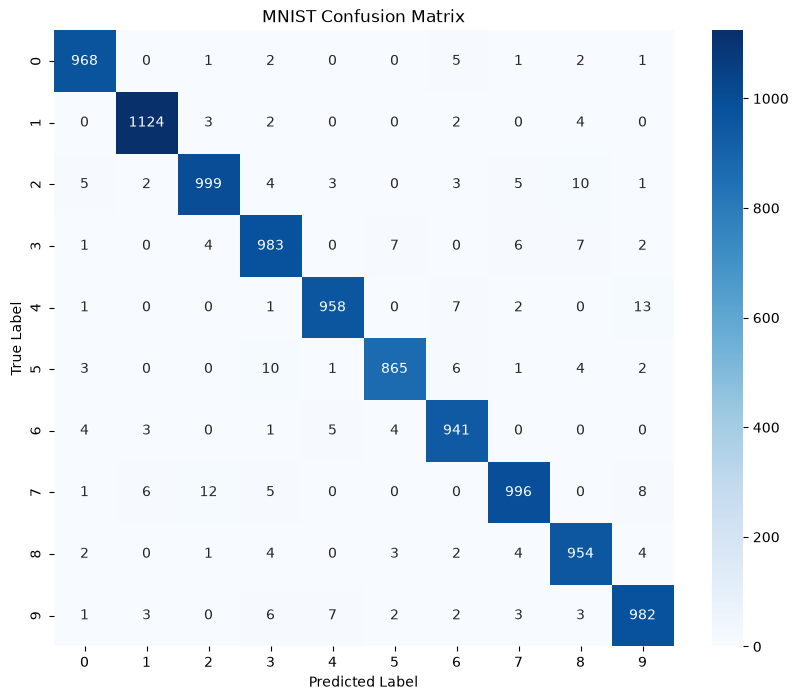

In [38]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MNIST Confusion Matrix")

plt.savefig(
    "../images/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation of the Confusion Matrix

The confusion matrix shows that most predictions are concentrated along the main diagonal, indicating that the model correctly classified most of the test images.

The off-diagonal values represent misclassifications, where the predicted digit differs from the actual digit.

For example, the matrix helps identify cases where visually similar handwritten digits may be confused.

Overall, the results indicate that the ANN performs well across the ten digit classes, although some classification errors remain.

## Step 12: Generate the classification report


The report includes four main metrics:

- **Precision:** Measures how many images predicted as a particular digit were actually that digit.
- **Recall:** Measures how many actual images of a particular digit were correctly identified by the model.
- **F1-score:** Represents the harmonic mean of precision and recall, balancing both metrics.
- **Support:** Indicates the number of actual test samples belonging to each digit class.

The report also provides macro and weighted averages to summarize performance across all ten classes.

In [39]:
from sklearn.metrics import classification_report

# Generate the classification report
report = classification_report(
    y_true,
    y_pred,
    digits=4
)

print(report)

              precision    recall  f1-score   support

           0     0.9817    0.9878    0.9847       980
           1     0.9877    0.9903    0.9890      1135
           2     0.9794    0.9680    0.9737      1032
           3     0.9656    0.9733    0.9694      1010
           4     0.9836    0.9756    0.9796       982
           5     0.9818    0.9697    0.9757       892
           6     0.9721    0.9823    0.9772       958
           7     0.9784    0.9689    0.9736      1028
           8     0.9695    0.9795    0.9745       974
           9     0.9694    0.9732    0.9713      1009

    accuracy                         0.9770     10000
   macro avg     0.9769    0.9768    0.9769     10000
weighted avg     0.9770    0.9770    0.9770     10000



### Interpretation of the Classification Report

The model achieved an overall accuracy of **97.70%** across the 10,000 test images.

The precision, recall, and F1-scores are consistently high across the ten digit classes, indicating that the model performs well in recognizing different handwritten digits.

The macro average calculates the unweighted average of the metrics across all classes, while the weighted average accounts for the number of samples in each class.

The similarity between the macro and weighted averages suggests that the model maintains relatively consistent classification performance across the digit classes.

## Step 13: Save your trained model

After training and evaluating the ANN, the trained model is saved in Keras format using the `.keras` file extension.

Saving the model preserves its learned architecture, weights, and configuration, allowing it to be loaded and used later without repeating the entire training process.

The saved model is stored in the `models` directory and is subsequently used by the DigitVision Streamlit application to make handwritten digit predictions.

In [40]:
# Save the trained model
model.save("../models/mnist_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!


## Step 14: View your TensorBoard training logs

In this project, TensorBoard is used to visualize:

- **Training Accuracy:** Shows how the model's accuracy changes on the training dataset.
- **Validation Accuracy:** Shows how accurately the model classifies images in the validation dataset.
- **Training Loss:** Tracks prediction error on the training dataset.
- **Validation Loss:** Tracks prediction error on the validation dataset.

These metrics help assess the model's learning progress and identify potential differences between training and validation performance.

## Step 14.1: Check the correct log directory

In [41]:
from pathlib import Path
from datetime import datetime
from tensorflow.keras.callbacks import TensorBoard

log_dir = "../logs/fit/" + datetime.now().strftime("%Y%m%d-%H%M%S")

tensorboard_callback = TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

In [44]:
%load_ext tensorboard
%tensorboard --logdir ../logs/fit

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 26940), started 0:42:09 ago. (Use '!kill 26940' to kill it.)

### Interpretation of TensorBoard Results

The TensorBoard dashboard provides a visual summary of the model's training and validation metrics over successive epochs.

The accuracy and loss trends help demonstrate how the model learns throughout training.

Comparing training and validation metrics also provides insight into how well the model generalizes to unseen data.

TensorBoard complements the Matplotlib visualizations by providing an interactive environment for monitoring the training process.